# Results: four anomalies, long-short backtest

Four signals, two universes (largest 500 and largest 3000 US common stocks by market cap), 1999 to 2026.

Each month-end we sort the universe into 10 groups by score, hold every group for the next month with
equal weights, and look at **long-short = top group minus bottom group**.

All returns are **before transaction costs**.

| Signal | Score at month-end t (higher = buy) |
|---|---|
| momentum | return from t-12 to t-1 |
| short_term_reversal | minus the return of month t |
| low_volatility | minus the idiosyncratic volatility of month t |
| post_earnings_drift | latest earnings surprise (SUE), used for three months |

---
# Part A. The four signals: construction and economics

For each signal: the exact recipe in `signals.py`, what the original paper found, why the effect might
exist, and how to read our own result.

**Timing, common to all four.** A score at month-end $t$ uses only information known at the close of the
last trading day of month $t$. We form the portfolio at that close and hold it during month $t+1$.
(Trading at the same close that we use to compute the score is the usual academic assumption; a real
strategy would trade a little later.)

**Three possible reasons any anomaly exists.** Keep these in mind for each signal:

1. **Risk.** The long-short portfolio loses money in bad times, so its average return is a fair reward
   for carrying that risk.
2. **Mispricing that is hard to trade away.** Investors make a systematic mistake, and costs, short-sale
   limits or the risk of large drawdowns stop arbitrageurs from fully correcting it
   ("limits to arbitrage").
3. **Luck.** Researchers tested hundreds of signals; some look good by chance and fade after publication.

## A.1 Momentum (Jegadeesh and Titman 1993)

### Construction

$$\text{score}_{i,t} = \frac{P_{i,t-1}}{P_{i,t-12}} - 1$$

$P$ is the month-end adjusted close (splits and dividends included), so the score is the total return over
the 11 months from the end of month $t-12$ to the end of month $t-1$.

```
month:    t-12   t-11   ...   t-2    t-1  |   t   |  t+1
          [------ score: 11 months ------]   skip    hold
```

- **Why skip month $t$.** One-month returns tend to reverse (that is signal A.2). Including the latest
  month would mix a reversal effect into a continuation signal.
- **Data needed.** 13 month-end prices. A stock listed for less than a year has no score.
- This "12-2" version is the one used in the Carhart (1997) four-factor model and in the Ken French
  momentum portfolios. The original paper tests many pairs of look-back and holding periods (3 to 12
  months each).

### What the paper found

US stocks, 1965 to 1989: buying past winners and shorting past losers earned about 1% per month.
The profit continues for up to a year and then **partly reverses over years 2 to 5**.

### Why it might work

- **Underreaction.** News spreads slowly across investors (Hong and Stein 1999), and people update their
  beliefs too little after new information (Barberis, Shleifer and Vishny 1998). The price moves only
  part of the way at first and keeps moving in the same direction afterwards.
- **Disposition effect.** Investors sell winners too early to lock in a gain and hold losers too long to
  avoid realising a loss (Grinblatt and Han 2005). Selling pressure on winners and missing selling
  pressure on losers both slow down the price adjustment.
- **Delayed overreaction.** Overconfident investors keep pushing prices in the same direction past fair
  value (Daniel, Hirshleifer and Subrahmanyam 1998). This story also explains the long-run reversal.
- **Risk: momentum crashes** (Daniel and Moskowitz 2016). After a market crash the loser group is full of
  beaten-down, high-beta stocks. When the market rebounds, those stocks rebound most, and momentum is
  short them. The strategy has rare but very large losses.

### Our result

Mean 0.72% to 0.91% per month, close to the paper's size, but the t-stat is below 2 because the
volatility is high. The spring 2009 crash is the textbook momentum crash, and it accounts for most of
the 75% drawdown. The 10 group returns rise steadily from group 1 to group 10.

## A.2 Short-term reversal (Jegadeesh 1990)

### Construction

$$\text{score}_{i,t} = -\left(\frac{P_{i,t}}{P_{i,t-1}} - 1\right)$$

Minus the return of month $t$: last month's biggest losers get the highest scores and are bought;
last month's biggest winners are shorted.

- **Data needed.** Two month-end prices.
- **Turnover.** The score is completely new every month, so almost the whole portfolio is replaced each
  month. This is by far the most expensive of the four signals to trade.

### What the paper found

US stocks, 1934 to 1987: monthly returns are negatively correlated with the previous month's return.
The top-minus-bottom decile portfolio earned about 2.5% per month. Lehmann (1990) found the same
pattern at the weekly horizon.

### Why it might work

- **Payment for providing liquidity.** When an investor must sell quickly, the price has to fall below
  fair value to attract a buyer. Whoever buys earns the rebound. A reversal strategy does this
  mechanically: it buys what others were selling and sells what others were buying. Nagel (2012) shows
  reversal profits are high when the VIX is high, that is, when liquidity is scarce and its price is high.
- **Bid-ask bounce.** If the last trade of the month happened at the bid, the measured return is too low,
  and next month it looks like a rebound even though the fair value did not move. This part is a
  measurement effect and cannot be earned.
- **Overreaction** to news that is then corrected.

### Our result

About zero in both universes, and the group returns form a hump: both extreme groups earn less than
the middle. Likely reasons:

- Our universe excludes micro-caps, where illiquidity (and so the reversal) is strongest.
- Spreads have fallen sharply since decimalization in 2001, and many more participants now provide
  liquidity, so the payment for it at a monthly horizon is small.
- The raw signal buys every loser, including stocks that fell on real bad news and keep falling
  (momentum and post-earnings drift work against it; see the negative correlations in section 7).

The versions that still work in the literature are shorter-horizon (days) and use the return **relative
to the industry or to factor exposures**, which removes the news-driven part and keeps the
liquidity-driven part (Da, Liu and Schaumburg 2014). That is the starting point of statistical
arbitrage.

## A.3 Low idiosyncratic volatility (Ang, Hodrick, Xing and Zhang 2006)

### Construction

For each stock $i$, using only the trading days $d$ of month $t$, run one regression of the stock's
daily excess return on the three Fama-French factors:

$$r_{i,d} - RF_d = a_i + b_i \, MKT_d + s_i \, SMB_d + h_i \, HML_d + e_{i,d}$$

- $MKT$: market return minus the risk-free rate. $SMB$: small stocks minus big stocks.
  $HML$: value stocks minus growth stocks.
- The residual $e_{i,d}$ is the part of the stock's move on day $d$ that these three factors do not
  explain: the stock's own, company-specific move.

$$\text{IVOL}_{i,t} = \text{std}(e_{i,d}), \qquad \text{score}_{i,t} = -\,\text{IVOL}_{i,t}$$

- **Degrees of freedom.** The standard deviation divides by (number of days $-$ 4), because the
  regression estimated four coefficients.
- **Data needed.** A return on every trading day of the month, and at least 15 trading days.
- **Why residual volatility and not total volatility.** Total volatility mixes two things: how much the
  stock moves with the market and with styles (its betas), and how much it moves on its own. The paper's
  claim is about the second part.

### What the paper found

US stocks, 1963 to 2000: the fifth of stocks with the highest idiosyncratic volatility earned about 1%
per month **less** than the fifth with the lowest.

### Why this is a puzzle

Standard theory says idiosyncratic risk earns nothing, because it disappears in a diversified
portfolio. If investors are not diversified, it should earn a **positive** premium (Merton 1987).
A negative premium fits neither.

### Why it might work

- **Lottery preference.** Some investors like stocks with a small chance of a huge gain and overpay for
  them (Barberis and Huang 2008). High-volatility stocks are those lottery tickets, so their later
  returns are low. Bali, Cakici and Whitelaw (2011) show that the largest single-day return of the
  month captures much of the effect.
- **Short-sale limits.** Volatile stocks are risky and expensive to short. When such a stock is
  overpriced, arbitrageurs do not fully correct it; when it is underpriced, buying is easy. So
  overpricing survives and underpricing does not, and on average volatile stocks are overpriced
  (Stambaugh, Yu and Yuan 2015).
- **Benchmarked and leverage-limited investors.** A manager who cannot use leverage and wants to beat an
  index buys riskier stocks instead, which pushes their prices up (Baker, Bradley and Wurgler 2011;
  Frazzini and Pedersen 2014 make the same argument for beta).

### Our result

Positive but not significant (t = 0.8 to 1.25). The group chart matches the short-sale story: groups 2
to 10 are almost flat, and the whole effect is group 1 (the most volatile stocks) earning much less.
The profit is on the short side, exactly where trading is hardest. The large loss in 1999 to early 2000
is the tech bubble: the lottery tickets kept winning for a year before they collapsed.

## A.4 Post-earnings-announcement drift, PEAD (Bernard and Thomas 1989)

### Construction

**Step 1: the earnings surprise.** For quarter $q$, the "expected" earnings per share is the EPS of the
same quarter one year earlier (a seasonal random walk: it handles seasonality, for example a retailer's
strong fourth quarter).

$$\Delta_q = EPS_q - EPS_{q-4}$$

$$SUE_q = \frac{\Delta_q}{\text{std}(\Delta_{q-7}, \dots, \Delta_q)}$$

- SUE = standardized unexpected earnings. Dividing by the standard deviation of the company's own past
  changes makes companies comparable: a 5-cent surprise is large for a stable utility and small for a
  volatile biotech.
- The standard deviation uses the latest 8 quarters and needs at least 6.
- EPS is diluted EPS as first reported (not later restated values), adjusted for splits.

**Step 2: the date the market learned it.** The first 8-K with item 2.02 ("results of operations", the
filing that carries the earnings press release) after the quarter ended. If there is none, the filing
date of the 10-Q or 10-K. Item 2.02 exists only since 2004, so before that we always use the 10-Q/10-K
date, which is later than the true announcement.

**Step 3: the monthly score.**

```
announcement in month m  ->  score at month-ends m, m+1, m+2  ->  held during months m+1, m+2, m+3
```

The SUE is first used at the first month-end strictly after the announcement and stays valid for three
month-ends, about the 60 trading days over which the paper measures the drift. A newer announcement
replaces the old one.

- **Data needed.** About 2.5 years of quarterly reports, which is why this signal starts in 2000-09.

### What the paper found

US stocks, 1974 to 1986: buying the top SUE decile and shorting the bottom decile earned about 4.2%
over the 60 trading days after the announcement, about 18% annualized. The effect was first documented by
Ball and Brown (1968).

### Why it might work

- **Underreaction to what this quarter says about the next ones.** Year-over-year earnings changes are
  positively autocorrelated: a good surprise this quarter tends to be followed by good surprises in the
  next three. Investors price as if earnings followed the naive seasonal random walk, and are then
  surprised again. Bernard and Thomas (1990) show that a large share of the drift arrives in the few days
  around the **next** earnings announcements, which is hard to explain as a reward for risk.
- **Limited attention.** The drift is larger when many companies announce on the same day
  (Hirshleifer, Lim and Teoh 2009) and for Friday announcements (DellaVigna and Pollet 2009).
- **Limits to arbitrage.** The drift is strongest in small, illiquid stocks with high trading costs.

### Our result

The only signal with a t-stat near 2, and the smallest drawdown (about -31%). The mean (0.38% per month)
is well below the paper's, for reasons that push in the same direction:

- **Our measurement loses the first days.** We wait until the next month-end to trade, so we miss on
  average half a month of drift, and before 2004 our announcement date is too late.
- **Our expectation is crude.** Practitioners measure the surprise against the analyst consensus, which
  is a better estimate of what the market expected than last year's quarter.
- **The effect has shrunk** since publication, especially in large stocks.

Note the 0.73 correlation with momentum in section 7: a company with good earnings news has usually
also gone up over the past year. Part of what is called momentum is earnings drift (Chan, Jegadeesh and
Lakonishok 1996).

---
# Part B. Backtest results

## 1. Run the backtest

Takes about 20 seconds. `portfolios[(signal, universe)]` is a table of monthly returns: columns 1..10 and `long_short`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from anomaly_replication.backtest import SIGNAL_COLORS, UNIVERSE_SIZES, plot_cumulative_returns, run_backtest
from anomaly_replication.portfolio import summarize

%matplotlib inline
pd.set_option("display.float_format", "{:.2f}".format)

portfolios = run_backtest()
long_short = pd.DataFrame({key: table["long_short"] for key, table in portfolios.items()})
(100 * long_short).tail()  # last five months, in %

momentum          short_term_reversal          low_volatility  \
            top 500 top 3000             top 500 top 3000        top 500   
date                                                                       
2026-06-30    13.16     5.61                1.45     3.12           5.30   
2026-07-31   -30.85   -20.75               18.76     6.43          15.36   
2026-08-31    -8.15    -8.32               -2.22    -3.38         -11.69   
2026-09-30    17.17     8.42               -2.18    -0.57          -8.92   
2026-10-30   -12.15    -5.96               17.38     7.82          20.51   

                    post_earnings_drift           
           top 3000             top 500 top 3000  
date                                              
2026-06-30     3.31               -1.87    -1.99  
2026-07-31    16.34               -2.24     3.06  
2026-08-31    -2.85               -3.60    -2.25  
2026-09-30     0.27                0.16     2.62  
2026-10-30    12.45               -4.81     2.15

## 2. Summary of the long-short portfolios

- **mean % per month**: average monthly return of top minus bottom.
- **t-stat**: mean / (std / sqrt(months)). Above 2 is the usual bar for "different from zero".
- **annual Sharpe**: mean / std * sqrt(12).
- **max drawdown %**: largest peak-to-trough loss of the cumulative value.

In [2]:
summary = pd.DataFrame({key: summarize(returns) for key, returns in long_short.items()}).T
summary

first month months mean % per month t-stat  \
momentum            top 500      1999-01    334             0.91   1.93   
                    top 3000     1999-01    334             0.72   1.59   
short_term_reversal top 500      1999-01    334            -0.11  -0.29   
                    top 3000     1999-01    334             0.10   0.28   
low_volatility      top 500      1999-01    334             0.36   0.80   
                    top 3000     1999-01    334             0.59   1.25   
post_earnings_drift top 500      2000-09    310             0.37   1.97   
                    top 3000     2000-09    310             0.38   2.19   

                             annual Sharpe max drawdown %  
momentum            top 500           0.37         -73.07  
                    top 3000          0.30         -76.80  
short_term_reversal top 500          -0.05         -78.02  
                    top 3000          0.05         -60.23  
low_volatility      top 500           0.15         -69.75  
                    top 3000          0.24         -73.57  
post_earnings_drift top 500           0.39         -33.67  
                    top 3000          0.43         -30.89

What to notice:

- Only **post-earnings drift** reaches a t-stat near 2, and its drawdown (about -31% to -34%) is less than half of the others.
- **Momentum** has the highest mean, but the t-stat is below 2 and the drawdown is above 70%.
- **Short-term reversal** is zero in both universes.
- **Low volatility** is positive but not significant.

## 3. Growth of $1

Log scale: the same vertical distance is the same percentage change.

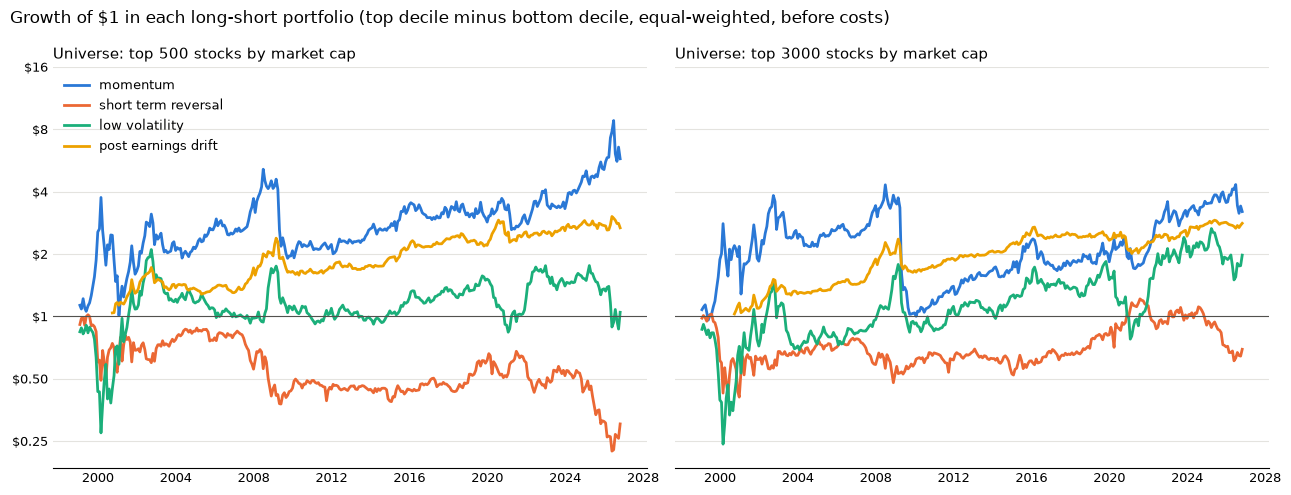

In [3]:
plot_cumulative_returns(long_short)

What to notice:

- **Momentum crash, spring 2009**: the stocks that fell most in 2008 rebounded hardest, and momentum was short them.
- **Low volatility, 1999 to early 2000**: high-volatility tech stocks went up a lot in the bubble, so the long-short lost; it recovered when the bubble burst.
- **Post-earnings drift** is the smoothest line.

## 4. Average return of each of the 10 groups

If a signal works, the bars should rise from group 1 (lowest score) to group 10 (highest score).
A long-short return that comes only from one extreme group is weaker evidence than a steady slope.

In [4]:
decile_means = pd.DataFrame({key: 100 * table.drop(columns="long_short").mean() for key, table in portfolios.items()}).T
decile_means

group                           1    2    3    4    5    6    7    8    9   10
momentum            top 500  0.38 0.68 0.81 0.80 0.84 0.96 0.85 0.90 0.92 1.28
                    top 3000 0.51 0.74 0.90 0.91 0.92 0.97 0.99 0.96 1.08 1.23
short_term_reversal top 500  0.74 0.80 0.69 0.89 0.84 0.89 0.90 1.04 0.87 0.63
                    top 3000 0.73 0.69 0.79 0.85 0.97 1.03 1.01 0.98 0.90 0.83
low_volatility      top 500  0.50 0.84 0.76 0.82 0.82 0.92 0.83 0.93 0.99 0.87
                    top 3000 0.30 0.74 0.86 0.96 1.04 1.00 1.02 0.96 1.02 0.89
post_earnings_drift top 500  0.56 0.79 0.89 0.83 0.90 0.86 0.91 0.85 0.86 0.94
                    top 3000 0.73 0.82 0.79 0.91 0.87 1.06 1.05 1.00 1.14 1.11

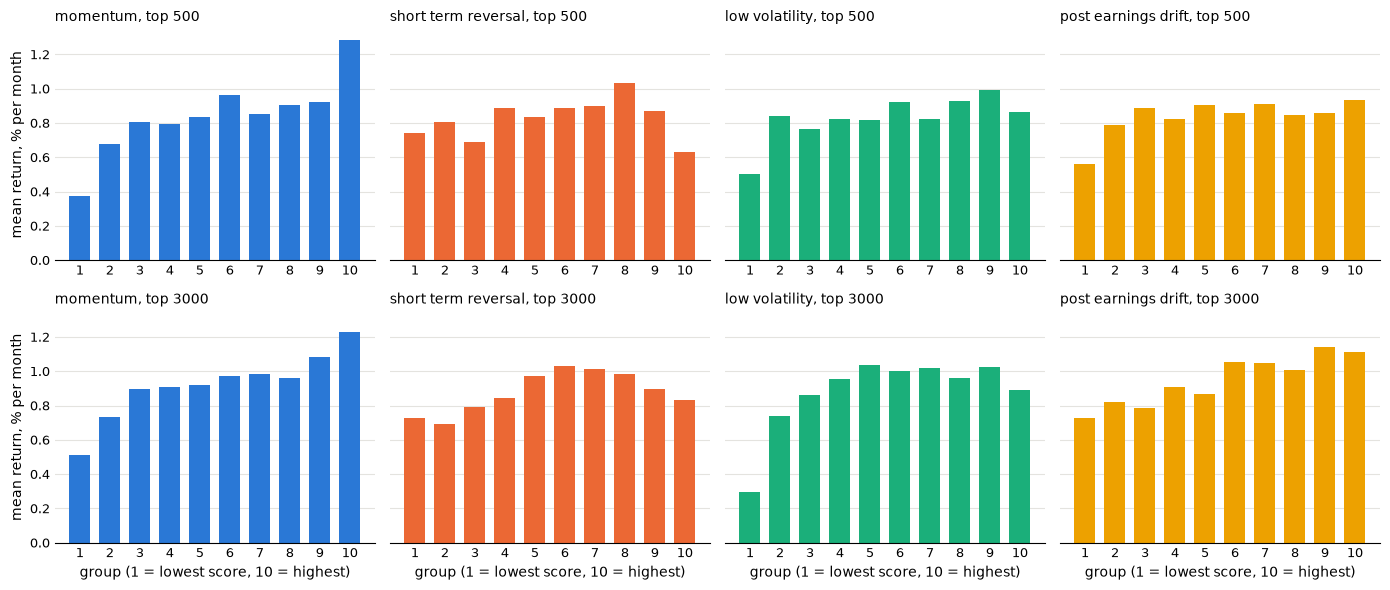

In [5]:
figure, axes = plt.subplots(len(UNIVERSE_SIZES), len(SIGNAL_COLORS), figsize=(14, 6), sharey=True)
for row, universe_name in enumerate(UNIVERSE_SIZES):
    for column, (signal_name, color) in enumerate(SIGNAL_COLORS.items()):
        axis = axes[row, column]
        means = decile_means.loc[(signal_name, universe_name)]
        axis.bar(means.index.astype(str), means, color=color, width=0.7)
        axis.set_title(f"{signal_name.replace('_', ' ')}, {universe_name}", loc="left", fontsize=10)
        axis.grid(axis="y", color="#e4e3df", linewidth=0.8)
        axis.set_axisbelow(True)
        axis.spines[["top", "right", "left"]].set_visible(False)
        axis.tick_params(length=0, labelsize=9)
    axes[row, 0].set_ylabel("mean return, % per month")
for axis in axes[-1]:
    axis.set_xlabel("group (1 = lowest score, 10 = highest)")
figure.tight_layout()
plt.show()

What to notice:

- **Momentum** rises steadily from group 1 to group 10: the cleanest slope of the four.
- **Short-term reversal** is a hump: both extreme groups earn less than the middle, so top minus bottom is about zero.
- **Low volatility**: groups 2 to 10 are almost flat. The whole effect is group 1 (the most volatile stocks)
  earning much less, so the profit comes from the short side.
- **Post-earnings drift** rises in the top 3000; in the top 500 it is again mostly group 1.

## 5. Two sub-periods

Mean long-short return (% per month) and t-stat in 1999-2009 and in 2010-2026.

In [6]:
periods = {"1999-2009": slice("1999", "2009"), "2010-2026": slice("2010", "2026")}
rows = {}
for period_name, years in periods.items():
    statistics = pd.DataFrame({key: summarize(returns.loc[years]) for key, returns in long_short.items()}).T
    rows[(period_name, "mean % per month")] = statistics["mean % per month"]
    rows[(period_name, "t-stat")] = statistics["t-stat"]
pd.DataFrame(rows).astype(float)

1999-2009               2010-2026       
                             mean % per month t-stat mean % per month t-stat
momentum            top 500              1.24   1.23             0.69   1.65
                    top 3000             0.73   0.74             0.71   1.84
short_term_reversal top 500             -0.19  -0.23            -0.06  -0.16
                    top 3000            -0.04  -0.05             0.19   0.57
low_volatility      top 500              0.72   0.72             0.13   0.34
                    top 3000             0.60   0.61             0.59   1.30
post_earnings_drift top 500              0.56   1.34             0.28   1.47
                    top 3000             0.56   1.40             0.29   1.77

## 6. Return by calendar year

Compounded long-short return of each year, in %. Shows which years made or lost the money.

In [7]:
yearly = 100 * ((1 + long_short.fillna(0)).groupby(long_short.index.year).prod() - 1)
yearly = yearly.where(long_short.groupby(long_short.index.year).count() > 0)  # blank before a signal starts
yearly.style.format("{:.0f}", na_rep="").background_gradient(cmap="RdBu", vmin=-60, vmax=60)

## 7. Correlation between the long-short portfolios

Monthly return correlation in the top 3000 universe. Low or negative correlation means two signals
diversify each other.

In [8]:
top_3000 = long_short.xs("top 3000", axis=1, level=1)
top_3000.corr()

,momentum,short_term_reversal,low_volatility,post_earnings_drift
momentum,1.00,-0.33,0.16,0.73
short_term_reversal,-0.33,1.00,-0.18,-0.30
low_volatility,0.16,-0.18,1.00,0.57
post_earnings_drift,0.73,-0.30,0.57,1.00


Momentum and post-earnings drift are strongly correlated (0.73): a stock with good earnings news has usually
also gone up over the past year, so the two signals pick many of the same stocks. Reversal is negatively
correlated with the other three.

## 8. What is not in these numbers

- **Transaction costs.** Short-term reversal replaces most of the portfolio every month, so it is hit hardest.
- **Delisting returns.** A stock with no price in the holding month is dropped (about 0.4% of stock-months).
- **Independent check.** Momentum and reversal were compared with the Ken French portfolios
  (long-short correlation 0.81 to 0.83). Low volatility and post-earnings drift have not been checked
  against an outside source yet.